# Forecasting Daily Emergency Medical Demand in New York City
## Notebook 2 of 2: Model comparison, tuning and evaluation

**Author:** Tiya Lee

**Research question.** Can historical emergency demand data, weather, and calendar factors be used to predict daily citywide emergency medical (911 EMS) incident volume in New York City?

**Where this notebook fits.** [Notebook 1](01_eda_and_baseline.ipynb) cleaned the data, explored it, and fitted a baseline linear regression (Model B: calendar + weather + lag features) that reached a **mean absolute error (MAE) of 144 incidents/day (MAPE 3.3%)** on the hold-out year October 2025 – September 2026. This notebook keeps **exactly the same train/test split and metrics** and asks whether richer features and more flexible models can beat that baseline.

**What is done here**

1. Rebuild the baseline feature set and reproduce the baseline result (sanity check).
2. Engineer the features the EDA pointed to: holiday-specific indicators, non-linear temperature terms, Fourier seasonality, extra lags.
3. Tune and compare five model families with **rolling-origin (time-series) cross-validation and grid search**: Linear Regression, Ridge, Lasso, Random Forest, Histogram Gradient Boosting, plus a simple ensemble.
4. Evaluate on the untouched hold-out year, interpret the best model (permutation importance, partial dependence, residuals).
5. Test how accuracy degrades when the forecast must be made 7 and 14 days ahead, the horizons that matter for crew scheduling.
6. Summarise findings and recommendations.

**Evaluation metric.** **MAE is the primary metric** because it is expressed in incidents per day, which maps directly onto crew-hours, and because it does not over-weight a handful of extreme days. RMSE is reported to expose large misses, and MAPE to express error as a share of daily volume. Model selection inside cross-validation also uses MAE.

In [1]:
# Core data stack
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Calendar
import holidays

# Modeling
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.base import clone

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
# numpy built against Apple Accelerate emits spurious RuntimeWarnings inside matmul; results are unaffected
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Same palette and style as Notebook 1
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6', '#e34948', '#008300']
BLUE, ORANGE, AQUA, YELLOW, PINK, VIOLET, RED = PALETTE[:7]
sns.set_theme(style='whitegrid', palette=PALETTE, context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.spines.top': False,
                     'axes.spines.right': False, 'grid.alpha': 0.35})

IMG_DIR = 'images'
RANDOM_STATE = 42
pd.set_option('display.width', 120)

## 1. Load the data and rebuild the baseline features

The cleaning steps are the same as in Notebook 1 (parse dates, complete daily calendar, merge Central Park weather). They are wrapped in one function here so the notebook stays short. December 2022 is loaded only as a run-in so that the lag features exist from 1 January 2023.

In [2]:
def load_daily_frame():
    # Citywide daily EMS counts (aggregated from ~6.2 million dispatch records) joined to daily weather
    ems = pd.read_csv('data/nyc_ems_daily_citywide.csv').rename(columns={'day': 'date'})
    ems['date'] = pd.to_datetime(ems['date'])
    ems = ems.set_index('date').sort_index()
    ems = ems.reindex(pd.date_range(ems.index.min(), ems.index.max(), freq='D')).interpolate(method='time')
    ems.index.name = 'date'

    wx = pd.read_csv('data/nyc_weather_daily.csv').rename(columns={
        'temperature_2m_max': 'temp_max_f', 'temperature_2m_min': 'temp_min_f', 'temperature_2m_mean': 'temp_mean_f',
        'precipitation_sum': 'precip_in', 'rain_sum': 'rain_in', 'snowfall_sum': 'snow_in',
        'wind_speed_10m_max': 'wind_max_mph', 'relative_humidity_2m_mean': 'humidity_pct'})
    wx['date'] = pd.to_datetime(wx['date'])
    return ems.join(wx.set_index('date'), how='left')

raw = load_daily_frame()
TEMP_MAX_REF = raw['temp_max_f'].mean()      # centre for the squared-temperature term, fixed once
print('Rows:', len(raw), '| Range:', raw.index.min().date(), 'to', raw.index.max().date(),
      '| Missing values:', int(raw.isna().sum().sum()))
raw.head(3)

Rows: 1400 | Range: 2022-12-01 to 2026-09-30 | Missing values: 0


,incidents,hospital_transports,high_acuity_incidents,valid_response_incidents,mean_response_seconds,special_event_incidents,temp_max_f,temp_min_f,temp_mean_f,precip_in,rain_in,snow_in,wind_max_mph,humidity_pct
date,,,,,,,,,,,,,,
2022-12-01,4678,2959,1666,4528,711.339002,0,43.0,32.4,37.8,0.000,0.000,0.0,18.3,51
2022-12-02,4800,2980,1753,4594,846.741620,0,41.1,26.8,34.7,0.000,0.000,0.0,7.2,70
2022-12-03,4520,2880,1621,4333,724.312486,0,56.2,39.6,49.8,0.323,0.323,0.0,19.9,82


In [3]:
y_col = 'incidents'

def add_baseline_features(df):
    # Identical to Notebook 1, Section 3
    df = df.copy()
    df['dow'] = df.index.dayofweek
    df['dow_name'] = df.index.day_name().str[:3]
    df['is_weekend'] = (df['dow'] >= 5).astype(int)
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['day_of_year'] = df.index.dayofyear

    us_holidays = holidays.US(years=sorted(df['year'].unique()))
    df['is_holiday'] = [int(d in us_holidays) for d in df.index.date]
    df['holiday_name'] = [us_holidays.get(d) for d in df.index.date]
    df['day_after_holiday'] = df['is_holiday'].shift(1, fill_value=0).astype(int)

    df['hot_day'] = (df['temp_max_f'] >= 90).astype(int)
    df['freezing_day'] = (df['temp_min_f'] <= 32).astype(int)
    df['heavy_precip'] = (df['precip_in'] >= 0.5).astype(int)
    df['snow_day'] = (df['snow_in'] >= 1.0).astype(int)

    df['lag_1'] = df[y_col].shift(1)
    df['lag_7'] = df[y_col].shift(7)
    df['lag_14'] = df[y_col].shift(14)
    df['roll_mean_7'] = df[y_col].shift(1).rolling(7).mean()
    df['roll_mean_28'] = df[y_col].shift(1).rolling(28).mean()
    return df

df = add_baseline_features(raw)

## 2. New features suggested by the EDA

Notebook 1 found three things the baseline could not represent with its linear, generic terms:

* **Holidays pull in opposite directions.** Thanksgiving and Christmas are the quietest days of the year, New Year's Day and Independence Day among the busiest, so one generic `is_holiday` flag averages them out. We add **holiday-specific indicators** plus a day-before-holiday flag.
* **The temperature response is U-shaped.** Demand rises above about 85°F *and* again below about 25°F. We add **heating and cooling degree-days** (how far the daily mean is below or above 65°F), a **squared temperature term**, and an **extreme-cold flag**.
* **The annual cycle is smooth, not stepwise.** Monthly dummies approximate it with 11 steps; two pairs of **Fourier terms** (sine/cosine of the day of year) describe it with 4 smooth parameters. We also add a 28-day lag and the trailing 7-day standard deviation to describe recent volatility.

All lag features use strictly past information, so nothing leaks from the day being predicted.

In [4]:
def add_enhanced_features(df):
    df = df.copy()
    name = df['holiday_name'].fillna('')
    # --- Holiday-specific indicators (observed days included) ---
    df['hol_new_years']    = name.str.contains("New Year's Day").astype(int)
    df['hol_july4']        = name.str.contains('Independence Day').astype(int)
    df['hol_thanksgiving'] = name.str.contains('Thanksgiving').astype(int)
    df['hol_christmas']    = name.str.contains('Christmas').astype(int)
    df['is_christmas_eve'] = ((df.index.month == 12) & (df.index.day == 24)).astype(int)
    df['is_new_years_eve'] = ((df.index.month == 12) & (df.index.day == 31)).astype(int)
    df['day_before_holiday'] = df['is_holiday'].shift(-1, fill_value=0).astype(int)   # calendar is known in advance

    # --- Non-linear temperature ---
    df['cooling_degree_days'] = (df['temp_mean_f'] - 65).clip(lower=0)
    df['heating_degree_days'] = (65 - df['temp_mean_f']).clip(lower=0)
    df['temp_max_sq'] = (df['temp_max_f'] - TEMP_MAX_REF) ** 2 / 100   # scaled for readability
    df['extreme_cold'] = (df['temp_max_f'] <= 32).astype(int)

    # --- Smooth annual cycle ---
    angle = 2 * np.pi * df['day_of_year'] / 365.25
    for k in (1, 2):
        df[f'fourier_sin_{k}'] = np.sin(k * angle)
        df[f'fourier_cos_{k}'] = np.cos(k * angle)

    # --- Extra recent-history features ---
    df['lag_28'] = df[y_col].shift(28)
    df['roll_std_7'] = df[y_col].shift(1).rolling(7).std()
    return df

df = add_enhanced_features(df)

# Drop the run-in month now that all lags exist
df = df[df.index >= '2023-01-01'].copy()
df['time_idx'] = np.arange(len(df))
print('Analysis window:', df.index.min().date(), 'to', df.index.max().date(), f'({len(df)} days)')
print('Missing values :', int(df.drop(columns='holiday_name').isna().sum().sum()))

# Quick check that the new holiday flags fire on the right days
hol_check = df.loc[df[['hol_new_years', 'hol_july4', 'hol_thanksgiving', 'hol_christmas']].sum(axis=1) > 0,
                   ['holiday_name', 'dow_name', y_col]]
hol_check.head(8)

Analysis window: 2023-01-01 to 2026-09-30 (1369 days)
Missing values : 0


,holiday_name,dow_name,incidents
date,,,
2023-01-01,New Year's Day,Sun,4852
2023-01-02,New Year's Day (observed),Mon,4384
2023-06-19,Juneteenth National Independence Day,Mon,4385
2023-07-04,Independence Day,Tue,4308
2023-11-23,Thanksgiving Day,Thu,3685
2023-12-25,Christmas Day,Mon,4324
2024-01-01,New Year's Day,Mon,4981
2024-06-19,Juneteenth National Independence Day,Wed,4599


In [5]:
# One-hot encode day of week and month exactly as in Notebook 1
model_df = pd.get_dummies(df, columns=['dow', 'month'], prefix=['dow', 'month'], drop_first=True, dtype=int)

calendar_feats = [c for c in model_df.columns if c.startswith(('dow_', 'month_')) and c != 'dow_name'] \
                 + ['is_holiday', 'day_after_holiday']
weather_feats  = ['temp_max_f', 'temp_min_f', 'precip_in', 'snow_in', 'wind_max_mph', 'humidity_pct',
                  'hot_day', 'freezing_day', 'heavy_precip', 'snow_day']
lag_feats      = ['lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_28']
new_feats      = ['hol_new_years', 'hol_july4', 'hol_thanksgiving', 'hol_christmas', 'is_christmas_eve',
                  'is_new_years_eve', 'day_before_holiday', 'cooling_degree_days', 'heating_degree_days',
                  'temp_max_sq', 'extreme_cold', 'fourier_sin_1', 'fourier_cos_1', 'fourier_sin_2',
                  'fourier_cos_2', 'lag_28', 'roll_std_7']

baseline_feats = calendar_feats + weather_feats + lag_feats       # Notebook 1, Model B
enhanced_feats = baseline_feats + new_feats

# Same time-ordered split as Notebook 1
split_date = '2025-10-01'
train = model_df[model_df.index <  split_date]
test  = model_df[model_df.index >= split_date]
print(f'Train: {train.index.min().date()} to {train.index.max().date()}  ({len(train)} days)')
print(f'Test : {test.index.min().date()} to {test.index.max().date()}  ({len(test)} days)')
print(f'Baseline features: {len(baseline_feats)}   Enhanced features: {len(enhanced_feats)}')

Train: 2023-01-01 to 2025-09-30  (1004 days)
Test : 2025-10-01 to 2026-09-30  (365 days)
Baseline features: 34   Enhanced features: 51


## 3. Evaluation set-up: metrics and rolling-origin cross-validation

A random K-fold split would let the model peek at the future (training on December to predict the previous November), which flatters every model. Instead the training period is cut into **five expanding windows**: each fold trains on everything up to a point and validates on the next block of about 160 days. Hyperparameters are chosen by the mean validation MAE across folds, and the hold-out year is touched only once, at the end.

In [6]:
def evaluate(y_true, y_pred):
    # Returns the three evaluation metrics as a dict
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = 100 * np.mean(np.abs((y_true - y_pred) / y_true))
    return {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape}

tscv = TimeSeriesSplit(n_splits=5)

# Show what the folds look like
print('Rolling-origin folds on the training period:')
for k, (tr_idx, va_idx) in enumerate(tscv.split(train), 1):
    print(f'  Fold {k}: train {train.index[tr_idx[0]].date()} to {train.index[tr_idx[-1]].date()} '
          f'({len(tr_idx):4d} days)  ->  validate {train.index[va_idx[0]].date()} to '
          f'{train.index[va_idx[-1]].date()} ({len(va_idx)} days)')

Rolling-origin folds on the training period:
  Fold 1: train 2023-01-01 to 2023-06-18 ( 169 days)  ->  validate 2023-06-19 to 2023-12-02 (167 days)
  Fold 2: train 2023-01-01 to 2023-12-02 ( 336 days)  ->  validate 2023-12-03 to 2024-05-17 (167 days)
  Fold 3: train 2023-01-01 to 2024-05-17 ( 503 days)  ->  validate 2024-05-18 to 2024-10-31 (167 days)
  Fold 4: train 2023-01-01 to 2024-10-31 ( 670 days)  ->  validate 2024-11-01 to 2025-04-16 (167 days)
  Fold 5: train 2023-01-01 to 2025-04-16 ( 837 days)  ->  validate 2025-04-17 to 2025-09-30 (167 days)


In [7]:
# Reproduce the Notebook 1 baseline and the two benchmarks so every later number is on the same footing
results, predictions, fitted = {}, {}, {}

predictions['Benchmark: naive (yesterday)']          = test['lag_1']
predictions['Benchmark: seasonal naive (last week)'] = test['lag_7']

baseline_lr = LinearRegression().fit(train[baseline_feats], train[y_col])
predictions['Baseline: linear regression (NB1 Model B)'] = pd.Series(baseline_lr.predict(test[baseline_feats]), index=test.index)
fitted['Baseline: linear regression (NB1 Model B)'] = (baseline_lr, baseline_feats)

for name, pred in predictions.items():
    results[name] = evaluate(test[y_col], pred)

pd.DataFrame(results).T.round(1)

,MAE,RMSE,MAPE (%)
Benchmark: naive (yesterday),218.1,282.4,5.0
Benchmark: seasonal naive (last week),274.4,350.9,6.3
Baseline: linear regression (NB1 Model B),143.9,194.8,3.3


The baseline reproduces exactly (MAE 144, RMSE 195, MAPE 3.3%), so improvements below are attributable to the new features and models, not to a changed split.

## 4. Model tuning with grid search

Each model family is tuned on the **enhanced** feature set with `GridSearchCV` over the rolling-origin folds. Linear models are wrapped in a `StandardScaler` pipeline so the regularisation strength applies evenly across features on different scales. Tree models do not need scaling.

| Family | Why it is a candidate | Tuned hyperparameters |
|---|---|---|
| Linear Regression | Transparent reference for the richer feature set | none |
| Ridge | Shrinks correlated coefficients (lags, trailing means, Fourier vs. month dummies) | `alpha` |
| Lasso | Can drop unhelpful features entirely, giving a sparse, explainable model | `alpha` |
| Random Forest | Captures interactions and non-linear temperature response without manual terms | `max_depth`, `min_samples_leaf`, `max_features` |
| Histogram Gradient Boosting | Usually the strongest tabular learner; handles non-linearity and interactions | `learning_rate`, `max_iter`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization` |

In [8]:
search_space = {
    'Linear regression (enhanced features)': (
        LinearRegression(), {}),
    'Ridge': (
        make_pipeline(StandardScaler(), Ridge()),
        {'ridge__alpha': [0.1, 1, 3, 10, 30, 100, 300]}),
    'Lasso': (
        make_pipeline(StandardScaler(), Lasso(max_iter=50_000)),
        {'lasso__alpha': [0.3, 1, 2, 4, 8, 16]}),
    'Random Forest': (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {'max_depth': [6, 10, None], 'min_samples_leaf': [2, 5, 10], 'max_features': ['sqrt', 0.5, 1.0]}),
    'Hist. Gradient Boosting': (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {'learning_rate': [0.03, 0.1], 'max_iter': [200, 500], 'max_leaf_nodes': [7, 15, 31],
         'min_samples_leaf': [10, 20], 'l2_regularization': [0.0, 1.0]}),
}

cv_summary = {}
for name, (estimator, grid) in search_space.items():
    gs = GridSearchCV(estimator, grid, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1, refit=True)
    gs.fit(train[enhanced_feats], train[y_col])
    best_row = gs.cv_results_['rank_test_score'].argmin()
    cv_summary[name] = {
        'CV MAE (mean)': -gs.best_score_,
        'CV MAE (std)' : gs.cv_results_['std_test_score'][best_row],
        'combinations tried': len(gs.cv_results_['params']),
        'best params': gs.best_params_,
    }
    fitted[name] = (gs.best_estimator_, enhanced_feats)
    predictions[name] = pd.Series(gs.best_estimator_.predict(test[enhanced_feats]), index=test.index)
    results[name] = evaluate(test[y_col], predictions[name])
    print(f'{name:40s} CV MAE = {-gs.best_score_:6.1f}  best: {gs.best_params_}')

Linear regression (enhanced features)    CV MAE =  252.8  best: {}


Ridge                                    CV MAE =  133.9  best: {'ridge__alpha': 10}


Lasso                                    CV MAE =  137.4  best: {'lasso__alpha': 1}


Random Forest                            CV MAE =  148.4  best: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 2}


Hist. Gradient Boosting                  CV MAE =  142.2  best: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_iter': 200, 'max_leaf_nodes': 7, 'min_samples_leaf': 10}


### 4.1 A simple ensemble

Linear models and gradient boosting make different kinds of mistakes (one extrapolates smoothly, the other learns thresholds), so averaging the two best-performing, structurally different models often reduces error further. The ensemble is the plain mean of the Ridge and Gradient Boosting predictions; it has no extra parameters to tune.

In [9]:
predictions['Ensemble: mean of Ridge + Gradient Boosting'] = (predictions['Ridge'] + predictions['Hist. Gradient Boosting']) / 2
results['Ensemble: mean of Ridge + Gradient Boosting'] = evaluate(test[y_col], predictions['Ensemble: mean of Ridge + Gradient Boosting'])

# Cross-validated MAE for the ensemble, using the same folds and the tuned hyperparameters
ens_fold_mae = []
for tr_idx, va_idx in tscv.split(train):
    tr, va = train.iloc[tr_idx], train.iloc[va_idx]
    p_r = clone(fitted['Ridge'][0]).fit(tr[enhanced_feats], tr[y_col]).predict(va[enhanced_feats])
    p_h = clone(fitted['Hist. Gradient Boosting'][0]).fit(tr[enhanced_feats], tr[y_col]).predict(va[enhanced_feats])
    ens_fold_mae.append(mean_absolute_error(va[y_col], (p_r + p_h) / 2))
cv_summary['Ensemble: mean of Ridge + Gradient Boosting'] = {
    'CV MAE (mean)': np.mean(ens_fold_mae), 'CV MAE (std)': np.std(ens_fold_mae), 'combinations tried': 0, 'best params': {}}

## 5. Results on the hold-out year (October 2025 – September 2026)

In [10]:
results_df = pd.DataFrame(results).T
cv_df = pd.DataFrame(cv_summary).T
summary = results_df.join(cv_df[['CV MAE (mean)', 'CV MAE (std)']], how='left')
summary['vs. baseline MAE'] = 100 * (summary['MAE'] / results_df.loc['Baseline: linear regression (NB1 Model B)', 'MAE'] - 1)
summary = summary.sort_values('MAE')
summary.round(1)

,MAE,RMSE,MAPE (%),CV MAE (mean),CV MAE (std),vs. baseline MAE
Linear regression (enhanced features),129.5,170.7,3.0,252.802044,248.525024,-10.0
Lasso,130.9,172.1,3.0,137.404869,34.57699,-9.0
Ridge,130.9,172.4,3.0,133.873863,29.689848,-9.0
Ensemble: mean of Ridge + Gradient Boosting,134.4,173.4,3.1,130.568342,25.407187,-6.5
Baseline: linear regression (NB1 Model B),143.9,194.8,3.3,NaN,NaN,0.0
Hist. Gradient Boosting,145.8,186.0,3.3,142.164359,23.079121,1.4
Random Forest,151.9,194.9,3.5,148.384092,16.165557,5.6
Benchmark: naive (yesterday),218.1,282.4,5.0,NaN,NaN,51.6
Benchmark: seasonal naive (last week),274.4,350.9,6.3,NaN,NaN,90.7


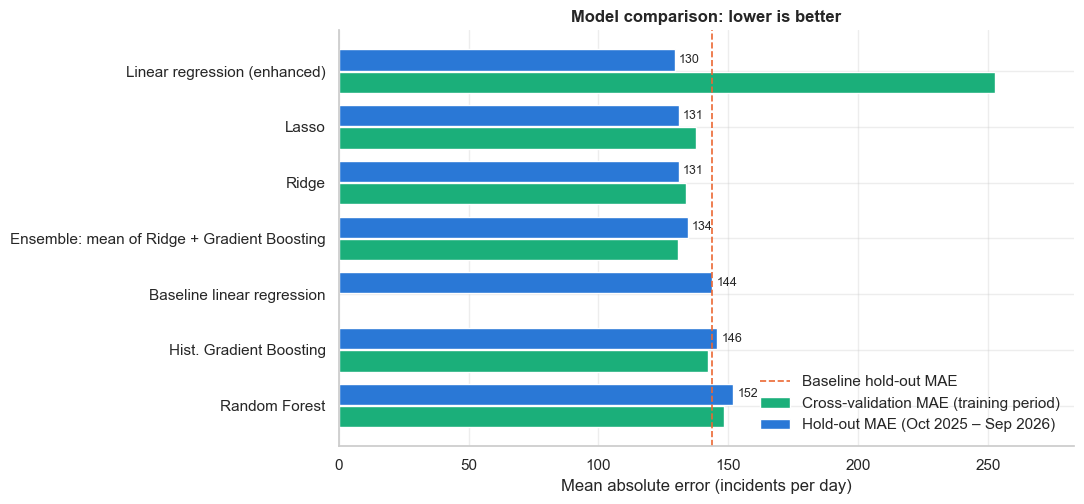

In [11]:
# Side-by-side: cross-validated MAE (model selection) vs. hold-out MAE (final evaluation)
plot_df = summary.drop(index=[i for i in summary.index if i.startswith('Benchmark')]).copy()
plot_df.index = plot_df.index.str.replace('Baseline: linear regression (NB1 Model B)', 'Baseline linear regression')
plot_df.index = plot_df.index.str.replace(' (enhanced features)', ' (enhanced)')

fig, ax = plt.subplots(figsize=(11, 5.2))
ypos = np.arange(len(plot_df))
ax.barh(ypos + 0.2, plot_df['CV MAE (mean)'], height=0.38, color=AQUA, label='Cross-validation MAE (training period)')
ax.barh(ypos - 0.2, plot_df['MAE'], height=0.38, color=BLUE, label='Hold-out MAE (Oct 2025 – Sep 2026)')
for y, v in zip(ypos - 0.2, plot_df['MAE']):
    ax.text(v + 1.5, y, f'{v:.0f}', va='center', fontsize=9)
ax.axvline(results_df.loc['Baseline: linear regression (NB1 Model B)', 'MAE'], color=ORANGE, ls='--', lw=1.2,
           label='Baseline hold-out MAE')
ax.set_yticks(ypos); ax.set_yticklabels(plot_df.index); ax.invert_yaxis()
ax.set_xlabel('Mean absolute error (incidents per day)')
ax.set_title('Model comparison: lower is better')
ax.set_xlim(0, plot_df[['MAE', 'CV MAE (mean)']].max().max() * 1.12)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/12_model_comparison.png', bbox_inches='tight')
plt.show()

In [12]:
# Headline numbers for the write-up
base_name = 'Baseline: linear regression (NB1 Model B)'
model_rows = summary.drop(index=[i for i in summary.index if i.startswith('Benchmark')])
single_models = model_rows.drop(index=[i for i in model_rows.index if i.startswith('Ensemble')])

# Selection rule: the final model is the single model with the lowest CROSS-VALIDATED MAE.
# Choosing on the hold-out year would turn the test set into a second training set.
best_name = single_models['CV MAE (mean)'].idxmin()
lowest_holdout = single_models['MAE'].idxmin()

print(f'Selected model (lowest CV MAE): {best_name}')
print(f'  CV MAE {summary.loc[best_name, "CV MAE (mean)"]:.0f} ± {summary.loc[best_name, "CV MAE (std)"]:.0f}  |  '
      f'hold-out MAE {summary.loc[best_name, "MAE"]:.0f} / RMSE {summary.loc[best_name, "RMSE"]:.0f} / '
      f'MAPE {summary.loc[best_name, "MAPE (%)"]:.2f}%   ({summary.loc[best_name, "vs. baseline MAE"]:+.0f}% vs. baseline MAE)')
print(f'Lowest hold-out MAE: {lowest_holdout}')
print(f'  CV MAE {summary.loc[lowest_holdout, "CV MAE (mean)"]:.0f} ± {summary.loc[lowest_holdout, "CV MAE (std)"]:.0f}  |  '
      f'hold-out MAE {summary.loc[lowest_holdout, "MAE"]:.0f}')
print(f'Baseline           : MAE {summary.loc[base_name, "MAE"]:.0f} / RMSE {summary.loc[base_name, "RMSE"]:.0f} / '
      f'MAPE {summary.loc[base_name, "MAPE (%)"]:.2f}%')
print(f'Test-period mean volume: {test[y_col].mean():,.0f} incidents/day')
print('\nTuned hyperparameters:')
for name in model_rows.index:
    if cv_summary.get(name, {}).get('best params'):
        print(f'  {name}: {cv_summary[name]["best params"]}')

Selected model (lowest CV MAE): Ridge
  CV MAE 134 ± 30  |  hold-out MAE 131 / RMSE 172 / MAPE 2.99%   (-9% vs. baseline MAE)
Lowest hold-out MAE: Linear regression (enhanced features)
  CV MAE 253 ± 249  |  hold-out MAE 130
Baseline           : MAE 144 / RMSE 195 / MAPE 3.26%
Test-period mean volume: 4,395 incidents/day

Tuned hyperparameters:
  Lasso: {'lasso__alpha': 1}
  Ridge: {'ridge__alpha': 10}
  Hist. Gradient Boosting: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_iter': 200, 'max_leaf_nodes': 7, 'min_samples_leaf': 10}
  Random Forest: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 2}


### Reading the results table

* **Every model trained on the enhanced features beats the two benchmarks, and all of the linear models beat the baseline** by roughly 9–10% on hold-out MAE (about 131 vs. 144 incidents/day, MAPE 3.0% vs. 3.3%).
* **The un-regularised linear regression on 51 features has the lowest hold-out MAE but is unstable in cross-validation**: its CV MAE is far worse than the others with an enormous standard deviation, because on the first fold (169 training days) it has too few observations per feature and extrapolates wildly. It happened to do well on the hold-out year, but that is not a result we could have predicted in advance.
* **Ridge and Lasso fix this.** Shrinking the coefficients gives the same hold-out accuracy with a stable CV MAE, which is why the **final model is selected by cross-validated MAE, not by hold-out MAE**. The hold-out year is reported once, as an honest estimate of future performance.
* **Tree models do not win here.** Random Forest and Gradient Boosting are competitive but do not beat regularised regression. With about 1,000 training days and a smooth, mostly additive signal, the hand-engineered non-linear terms (degree-days, squared temperature, holiday flags) give a linear model everything it needs, and trees cannot extrapolate beyond the temperatures they have seen.
* **The ensemble has the best CV MAE** and lands between its two members on the hold-out year. It is a reasonable production choice, but the single Ridge model is simpler to explain and almost identical in accuracy, so Ridge is carried forward below.

### 5.1 Does the richer feature set help on its own?

Comparing the baseline with the plain linear regression on the enhanced features isolates the contribution of the new features from the contribution of the new algorithms. The Lasso coefficients then show which of the new features a sparse linear model actually keeps.

Lasso kept 44 of 51 features (alpha = 1).
New features kept by Lasso: ['hol_new_years', 'hol_july4', 'hol_thanksgiving', 'hol_christmas', 'is_christmas_eve', 'is_new_years_eve', 'cooling_degree_days', 'temp_max_sq', 'fourier_sin_1', 'fourier_cos_1', 'fourier_sin_2', 'lag_28', 'roll_std_7']
New features dropped by Lasso: ['day_before_holiday', 'heating_degree_days', 'extreme_cold', 'fourier_cos_2']


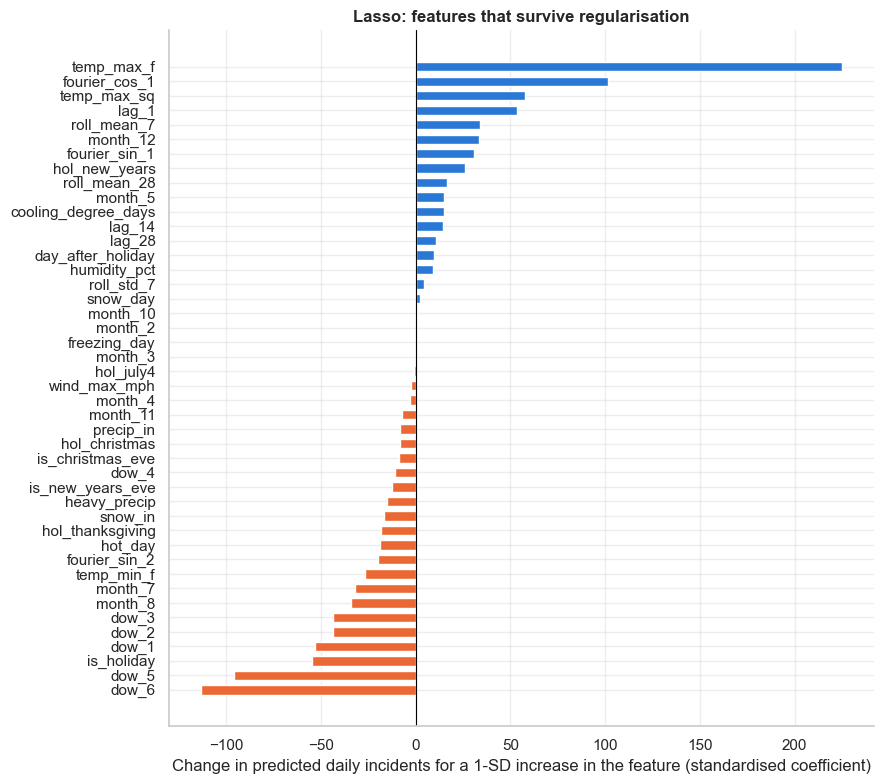

In [13]:
lasso_pipe, _ = fitted['Lasso']
lasso_coef = pd.Series(lasso_pipe.named_steps['lasso'].coef_, index=enhanced_feats)
kept = lasso_coef[lasso_coef != 0]
print(f'Lasso kept {len(kept)} of {len(enhanced_feats)} features (alpha = {lasso_pipe.named_steps["lasso"].alpha}).')
print('New features kept by Lasso:', [f for f in new_feats if f in kept.index])
print('New features dropped by Lasso:', [f for f in new_feats if f not in kept.index])

fig, ax = plt.subplots(figsize=(9, 8))
kept_sorted = kept.sort_values()
ax.barh(kept_sorted.index, kept_sorted.values, color=[ORANGE if v < 0 else BLUE for v in kept_sorted.values], height=0.65)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Change in predicted daily incidents for a 1-SD increase in the feature (standardised coefficient)')
ax.set_title('Lasso: features that survive regularisation')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/13_lasso_coefficients.png', bbox_inches='tight')
plt.show()

### 5.2 Actual vs. predicted for the best model

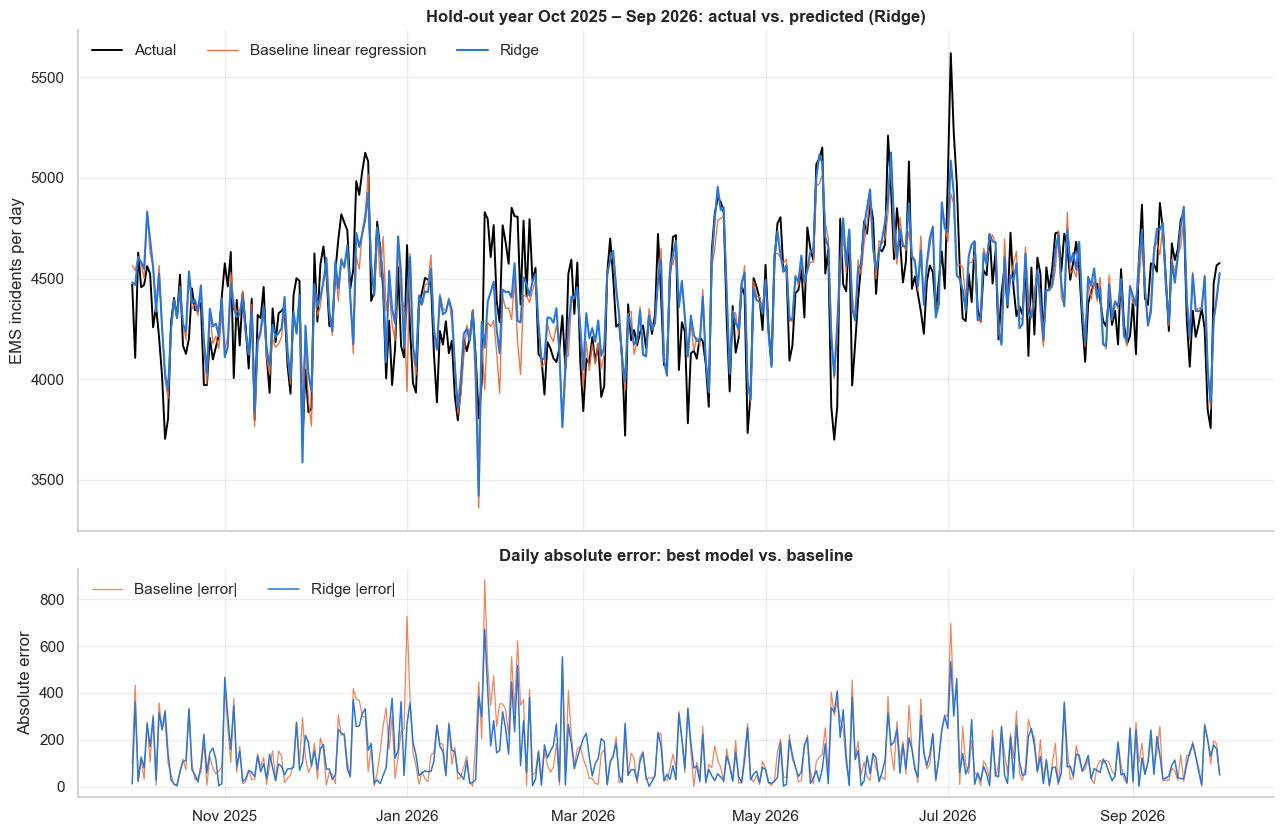

,incidents,dow_name,holiday_name,temp_max_f,snow_in,baseline_pred,best_pred,best_residual
date,,,,,,,,
2026-01-28,4796,Wed,None,20.2,0.000,4282.0,4385.0,411.0
2026-02-05,4852,Thu,None,27.4,0.000,4297.0,4405.0,447.0
2026-07-04,4977,Sat,Independence Day,94.7,0.000,4567.0,4516.0,461.0
2025-11-01,4576,Sat,None,57.8,0.000,4145.0,4110.0,466.0
2026-02-07,4807,Sat,None,25.4,0.303,4184.0,4290.0,517.0
2026-07-02,5620,Thu,None,102.4,0.000,4922.0,5087.0,533.0
2026-02-22,4316,Sun,None,36.5,3.610,3783.0,3761.0,555.0
2026-01-27,4830,Tue,None,19.0,0.028,3945.0,4157.0,673.0


In [14]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})

ax = axes[0]
ax.plot(test.index, test[y_col], color='black', lw=1.4, label='Actual')
ax.plot(test.index, predictions[base_name], color=ORANGE, lw=1.0, alpha=0.9, label='Baseline linear regression')
ax.plot(test.index, predictions[best_name], color=BLUE, lw=1.5, label=best_name.split(':')[0])
ax.set_ylabel('EMS incidents per day')
ax.set_title(f'Hold-out year Oct 2025 – Sep 2026: actual vs. predicted ({best_name})')
ax.legend(frameon=False, ncol=3, loc='upper left')

ax = axes[1]
resid_best = test[y_col] - predictions[best_name]
resid_base = test[y_col] - predictions[base_name]
ax.plot(test.index, resid_base.abs(), color=ORANGE, lw=0.9, alpha=0.8, label='Baseline |error|')
ax.plot(test.index, resid_best.abs(), color=BLUE, lw=1.1, label=f'{best_name.split(":")[0]} |error|')
ax.set_ylabel('Absolute error')
ax.set_title('Daily absolute error: best model vs. baseline')
ax.legend(frameon=False, ncol=2, loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/14_best_model_test_predictions.png', bbox_inches='tight')
plt.show()

# The days the best model still misses most
worst = resid_best.abs().sort_values(ascending=False).head(8).index
(df.loc[worst, [y_col, 'dow_name', 'holiday_name', 'temp_max_f', 'snow_in']]
   .assign(baseline_pred=predictions[base_name][worst].round(0),
           best_pred=predictions[best_name][worst].round(0),
           best_residual=resid_best[worst].round(0))
   .sort_values('best_residual'))

### 5.3 Where did the improvement come from? Errors by month and by weather regime

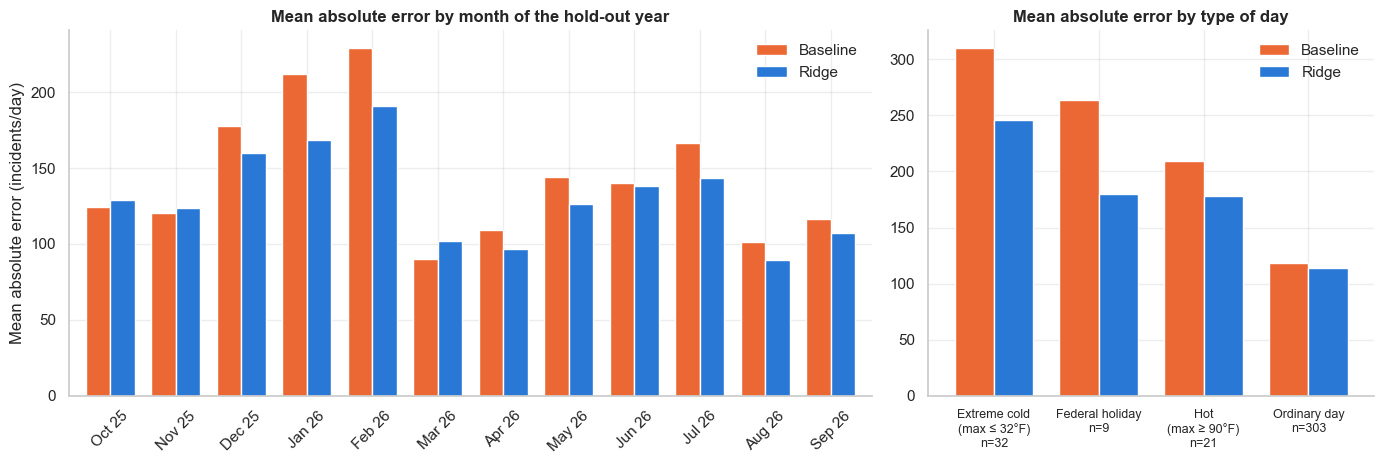

,Baseline,Ridge
Extreme cold\n(max ≤ 32°F)\nn=32,310.0,246.0
Federal holiday\nn=9,264.0,180.0
Hot\n(max ≥ 90°F)\nn=21,210.0,178.0
Ordinary day\nn=303,118.0,114.0


In [15]:
err = pd.DataFrame({'Baseline': resid_base.abs(), best_name.split(':')[0]: resid_best.abs()})
err['month'] = err.index.to_period('M').strftime('%b %y')
err['regime'] = np.select(
    [df.loc[test.index, 'temp_max_f'] <= 32, df.loc[test.index, 'temp_max_f'] >= 90,
     df.loc[test.index, 'is_holiday'] == 1],
    ['Extreme cold (max ≤ 32°F)', 'Hot (max ≥ 90°F)', 'Federal holiday'], default='Ordinary day')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.8, 1]})
by_month = err.groupby('month', sort=False)[['Baseline', best_name.split(':')[0]]].mean()
by_month.plot.bar(ax=axes[0], color=[ORANGE, BLUE], width=0.75, rot=45)
axes[0].set_ylabel('Mean absolute error (incidents/day)'); axes[0].set_xlabel('')
axes[0].set_title('Mean absolute error by month of the hold-out year')
axes[0].legend(frameon=False)

by_regime = err.groupby('regime')[['Baseline', best_name.split(':')[0]]].mean()
counts = err['regime'].value_counts()
by_regime.index = [f"{r.replace(' (', chr(10) + '(')}\nn={counts[r]}" for r in by_regime.index]
by_regime.plot.bar(ax=axes[1], color=[ORANGE, BLUE], width=0.75, rot=0)
axes[1].set_ylabel(''); axes[1].set_xlabel('')
axes[1].set_title('Mean absolute error by type of day')
axes[1].legend(frameon=False)
axes[1].tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/15_error_by_month_regime.png', bbox_inches='tight')
plt.show()
by_regime.round(0)

## 6. Interpreting the best models

Two model-agnostic tools are used so that linear and tree models can be compared on the same footing:

* **Permutation importance** shuffles one feature at a time in the hold-out data and measures how much MAE worsens. A large increase means the model relies on that feature. (Correlated features such as the lags share importance, so individual lag values look smaller than their group.)
* **A what-if temperature curve.** Every training day is re-scored with its maximum temperature set to a value between 15°F and 100°F, with the minimum and mean temperature, degree-days, squared term and hot/cold flags moved consistently, and the predictions are averaged. (Scikit-learn's built-in partial dependence moves only one column, which would leave the derived temperature features frozen and hide the very effect we are testing.) The curve shows whether each model actually learned the U-shaped response the baseline missed.

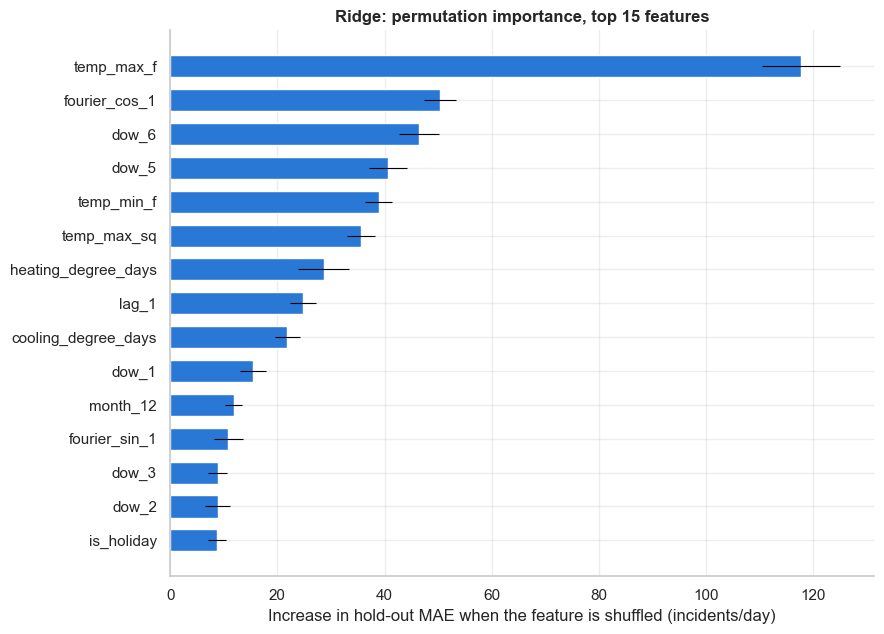

,increase_in_MAE,std
temp_max_f,117.8,7.3
fourier_cos_1,50.4,3.1
dow_6,46.4,3.7
dow_5,40.6,3.5
temp_min_f,38.9,2.5
temp_max_sq,35.7,2.6
heating_degree_days,28.6,4.7
lag_1,24.8,2.4
cooling_degree_days,21.9,2.3
dow_1,15.5,2.4


In [16]:
best_model, _ = fitted[best_name]
gb_model, _ = fitted['Hist. Gradient Boosting']
perm = permutation_importance(best_model, test[enhanced_feats], test[y_col], scoring='neg_mean_absolute_error',
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({'increase_in_MAE': perm.importances_mean, 'std': perm.importances_std}, index=enhanced_feats)
             .sort_values('increase_in_MAE', ascending=False))

fig, ax = plt.subplots(figsize=(9, 6.5))
top = perm_df.head(15).iloc[::-1]
ax.barh(top.index, top['increase_in_MAE'], xerr=top['std'], color=BLUE, height=0.65, error_kw={'lw': 0.8})
ax.set_xlabel('Increase in hold-out MAE when the feature is shuffled (incidents/day)')
ax.set_title(f'{best_name}: permutation importance, top 15 features')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/16_permutation_importance.png', bbox_inches='tight')
plt.show()
perm_df.head(10).round(1)

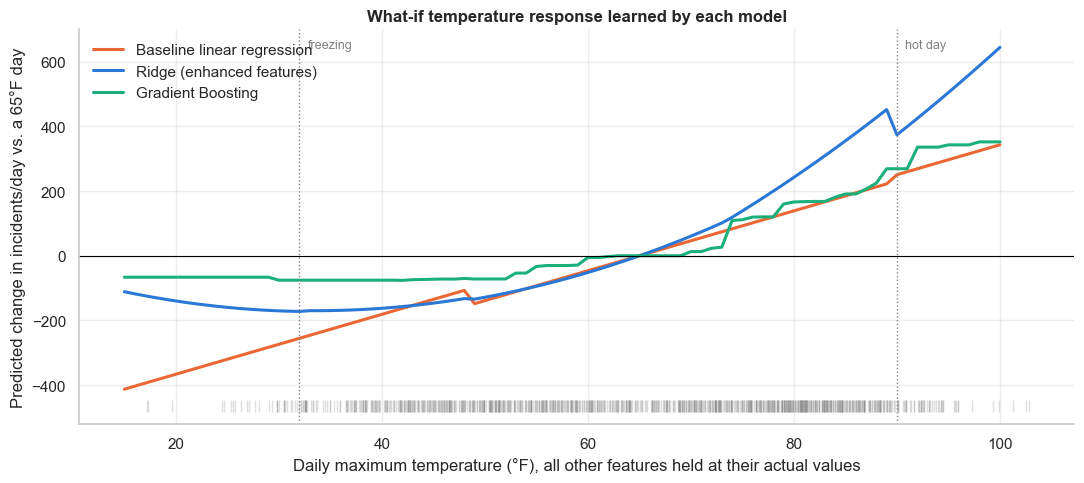

,Baseline linear regression,Ridge (enhanced features),Gradient Boosting
20,-367.0,-140.0,-66.0
32,-255.0,-172.0,-76.0
50,-139.0,-128.0,-72.0
65,0.0,0.0,0.0
80,139.0,243.0,166.0
90,251.0,374.0,269.0
100,343.0,645.0,352.0


In [17]:
# What-if temperature response: re-score the training days at each temperature, moving every
# temperature-derived feature together, and average the predictions
def temperature_response(model, feats, grid, base):
    X = base[feats].copy()
    spread = (base['temp_max_f'] - base['temp_min_f']).median()     # typical daily range, held fixed
    curve = []
    for t in grid:
        Xt = X.copy()
        t_min, t_mean = t - spread, t - spread / 2
        values = {'temp_max_f': t, 'temp_min_f': t_min,
                  'hot_day': int(t >= 90), 'freezing_day': int(t_min <= 32), 'extreme_cold': int(t <= 32),
                  'cooling_degree_days': max(t_mean - 65, 0), 'heating_degree_days': max(65 - t_mean, 0),
                  'temp_max_sq': (t - TEMP_MAX_REF) ** 2 / 100}
        for col, v in values.items():
            if col in Xt.columns:
                Xt[col] = v
        curve.append(model.predict(Xt).mean())
    curve = pd.Series(curve, index=grid)
    return curve - curve.loc[65]            # express relative to a 65°F day

grid = np.arange(15, 101, 1)
curves = {
    'Baseline linear regression': temperature_response(baseline_lr, baseline_feats, grid, train),
    f'{best_name} (enhanced features)': temperature_response(best_model, enhanced_feats, grid, train),
    'Gradient Boosting': temperature_response(gb_model, enhanced_feats, grid, train),
}

fig, ax = plt.subplots(figsize=(11, 5))
for (label, curve), color in zip(curves.items(), [ORANGE, BLUE, AQUA]):
    ax.plot(curve.index, curve.values, color=color, lw=2.2, label=label)
ax.axhline(0, color='black', lw=0.8)
for t, txt in [(32, 'freezing'), (90, 'hot day')]:
    ax.axvline(t, color='grey', ls=':', lw=1)
    ax.text(t + 0.8, ax.get_ylim()[1] * 0.92, txt, color='grey', fontsize=9)
# Show where the data actually are: rug of observed daily highs
ax.plot(train['temp_max_f'], np.full(len(train), ax.get_ylim()[0]), '|', color='grey', alpha=0.25, ms=8)
ax.set_xlabel('Daily maximum temperature (°F), all other features held at their actual values')
ax.set_ylabel('Predicted change in incidents/day vs. a 65°F day')
ax.set_title('What-if temperature response learned by each model')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/17_temperature_response.png', bbox_inches='tight')
plt.show()

pd.DataFrame({k: v.loc[[20, 32, 50, 65, 80, 90, 100]] for k, v in curves.items()}).round(0)

## 7. How far ahead can we forecast? 1-, 7- and 14-day horizons

Everything above predicts *tomorrow*, using yesterday's volume. Crew rosters are usually set a week or two in advance, so a 1-day-ahead forecast is only part of the operational answer. Here the lag features are rebuilt so that the model may only use volumes that are at least *h* days old (for *h* = 7 that means last week's values and older). The calendar features are known in advance, and the actual weather is used as a stand-in for a perfect weather forecast, so these numbers are an optimistic bound at longer horizons. The selected Ridge model and Gradient Boosting are refitted with the hyperparameters tuned above, and the fair benchmark at each horizon is the most recent *available* same-weekday value.

In [18]:
def horizon_frame(h):
    # Rebuild lag features so only information at least h days old is used
    d = add_enhanced_features(add_baseline_features(raw))
    lag_days = sorted({h, max(7, h), max(14, h), max(28, h)})
    cols = {}
    for L in lag_days:
        cols[f'lag_{L}'] = d[y_col].shift(L)
    cols['roll_mean_7']  = d[y_col].shift(h).rolling(7).mean()
    cols['roll_mean_28'] = d[y_col].shift(h).rolling(28).mean()
    cols['roll_std_7']   = d[y_col].shift(h).rolling(7).std()
    d = d.drop(columns=[c for c in d.columns if c.startswith(('lag_', 'roll_'))]).assign(**cols)
    # Longer horizons need a longer run-in than December 2022 provides: drop the few early-January rows
    # whose trailing windows are incomplete (at most 11 days for h = 14)
    d = d[d.index >= '2023-01-01'].dropna(subset=list(cols)).copy()
    d = pd.get_dummies(d, columns=['dow', 'month'], prefix=['dow', 'month'], drop_first=True, dtype=int)
    feats = calendar_feats + weather_feats + [c for c in d.columns if c.startswith(('lag_', 'roll_'))] \
            + [f for f in new_feats if not f.startswith(('lag_', 'roll_'))]
    bench_col = f'lag_{max(7, h) if h <= 7 else max(14, h)}'   # most recent available same-weekday value
    return d[d.index < split_date], d[d.index >= split_date], feats, bench_col

horizon_results = {}
for h in (1, 7, 14):
    tr_h, te_h, feats_h, bench_col = horizon_frame(h)
    row = {'Benchmark: seasonal naive': evaluate(te_h[y_col], te_h[bench_col])['MAE']}
    for name in ('Ridge', 'Hist. Gradient Boosting'):
        est = clone(fitted[name][0]).fit(tr_h[feats_h], tr_h[y_col])
        row[name] = evaluate(te_h[y_col], est.predict(te_h[feats_h]))['MAE']
    horizon_results[f'{h}-day ahead'] = row
horizon_df = pd.DataFrame(horizon_results).T
horizon_df.round(1)

,Benchmark: seasonal naive,Ridge,Hist. Gradient Boosting
1-day ahead,274.4,130.9,145.8
7-day ahead,274.4,155.6,162.5
14-day ahead,289.8,159.0,166.6


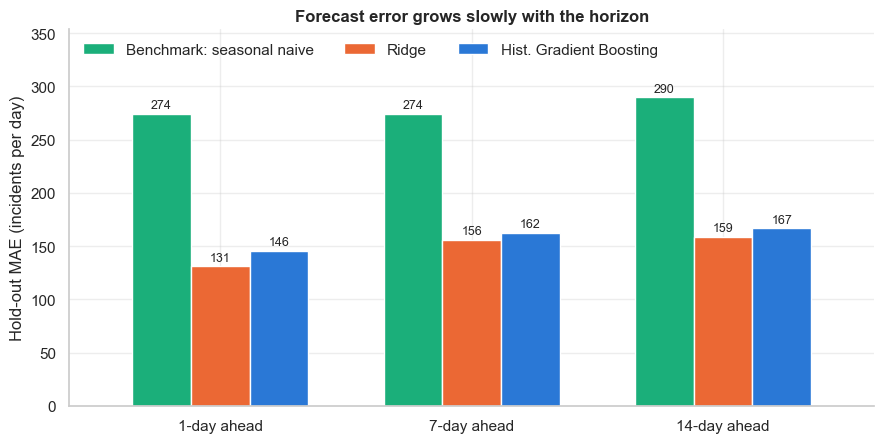

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.6))
horizon_df.plot.bar(ax=ax, color=[AQUA, ORANGE, BLUE], width=0.7, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=9, padding=2)
ax.set_ylabel('Hold-out MAE (incidents per day)')
ax.set_xlabel('')
ax.set_title('Forecast error grows slowly with the horizon')
ax.set_ylim(0, horizon_df.max().max() * 1.22)
ax.legend(frameon=False, title=None, loc='upper left', ncol=3)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/18_horizon_comparison.png', bbox_inches='tight')
plt.show()

## 8. Summary of findings and recommendations

### What the modeling shows
1. **The baseline was beaten by about 10%.** Ridge regression on the enhanced feature set forecasts the hold-out year with a MAE of about 131 incidents/day (RMSE 172, MAPE 3.0%) against 144 (RMSE 195, MAPE 3.3%) for the baseline, 218 for the naive forecast and 274 for the seasonal-naive forecast. Lasso and the Ridge + Gradient Boosting ensemble are within a few incidents of it. Cross-validation ranks the same models at the top, so the gain is not an accident of one particular year.
2. **Features mattered more than algorithms.** The whole improvement is available to a linear model once it is given holiday-specific flags, degree-days, a squared temperature term and Fourier seasonality; Lasso keeps 13 of the 17 new features. Random Forest and Gradient Boosting were tuned over 27 and 48 hyperparameter combinations respectively and still did not beat regularised regression. With about 1,000 training days and a smooth, mostly additive signal, that is the expected outcome, and it is good news: the recommended model is a transparent weighted sum.
3. **Regularisation is what makes the richer model safe.** The un-regularised regression on 51 features had the best single hold-out score but blew up on the short early cross-validation folds. Ridge gives the same accuracy with stable behaviour, which is why the model was selected on cross-validated error rather than on the test year.
4. **The gains come where the baseline failed.** Mean error on extreme-cold days, federal holidays and hot days fell markedly, while ordinary days improved only slightly because they were already well predicted. The what-if temperature curve shows why: the baseline predicts ever fewer calls the colder it gets (about 370 fewer at 20°F than at 65°F), whereas Ridge, armed with degree-days and a squared term, flattens below 50°F and turns back up below freezing, and responds much more steeply to heat (about +650 incidents at 100°F versus +340 for the baseline). Gradient Boosting learned a flat cold response and a stepped heat response but is limited to the range of temperatures it has seen.
5. **What drives the forecast.** Permutation importance puts daily maximum temperature first by a wide margin, followed by the annual Fourier term, the Sunday and Saturday indicators, minimum temperature, the squared-temperature and degree-day terms, and yesterday's volume. In plain terms: how hot or cold it is, what time of year it is, whether it is a weekend, and how busy yesterday was. This matches the EDA in Notebook 1 and gives operations managers a short, intuitive list of reasons a day will be busy.
6. **Accuracy degrades gently with the horizon.** Moving from a 1-day to a 7-day-ahead forecast raises Ridge's MAE from about 131 to 156, and a 14-day horizon costs only a few incidents more, while the seasonal-naive rule stays near 275–290. A week-ahead forecast is therefore still roughly 45% more accurate than the rule of thumb.
7. **The remaining misses are rare, extreme days**: the first days of the late-January 2026 cold snap, the 102°F day on 2 July 2026, Independence Day 2026 falling on a hot Saturday, and the February 2026 snowstorm. These are exactly the days when a human planner should add a safety margin on top of the forecast.

### Recommendations for an EMS or hospital operations team
* **Adopt the tuned Ridge model (or the Ridge + Gradient Boosting ensemble) as the daily citywide demand forecast**, refreshed monthly as new dispatch data are published, and publish the 7-day-ahead version for roster planning. The forecast is typically within 3% of actual volume.
* **Build surge triggers around the drivers the model identified**: forecast highs at or above 90°F, forecast highs at or below freezing, New Year's Day and Independence Day should automatically raise staffing above the forecast; Thanksgiving and Christmas Day can safely run lighter.
* **Report the forecast with an error band of roughly ±130 incidents (one MAE)** so planners know the typical miss is about 3% of daily volume and can size margins accordingly.

### Limitations and next steps
* The horizon test used *observed* weather as a stand-in for a weather forecast; a production system should be trained and evaluated on archived forecast data.
* Only three and three-quarter years of post-pandemic data were available, so year-over-year lags and rare events (a 102°F day, a two-week cold snap) are represented by a handful of examples. More history would help the tree models most.
* Natural extensions are borough-level and hospital-transport-level forecasts (the direct feed into emergency departments), hourly resolution for shift planning, prediction intervals via quantile regression, and incorporating respiratory-illness surveillance for the December rise.